<div dir="rtl" style="text-align:right; line-height:1.9;">
<h1>فاز دوم — گام سوم: توزیع پیوسته و بررسی تقریب نرمال</h1>
<p><strong>مسیر اول: بررسی سطح ویتامین دی در بزرگسالان هجده‌ساله و بالاتر</strong></p>
<p>در این گام، از همان دادهٔ ادغام‌شدهٔ فاز اول و همان جامعهٔ تحلیلی گام‌های اول و دوم استفاده می‌کنیم. هدف بررسی شکل توزیع سطح ویتامین دی، چولگی، پراکندگی، مقادیر دورافتاده و مناسب‌بودن تقریب نرمال است.</p>
<p><strong>پرسش:</strong> آیا منحنی نرمال می‌تواند شکل توزیع تجربی و به‌ویژه احتمال‌های انتهایی آن را به‌خوبی توصیف کند؟</p>
<p>نام متغیر اصلی در فایل داده:</p>
</div>

<div dir="ltr" style="text-align:left;"><code>LBXVIDMS</code></div>

<div dir="rtl" style="text-align:right; line-height:1.9;">
<p>واحد اندازه‌گیری: نانومول بر لیتر. در این مرحله آزمون فرض رسمی اجرا نمی‌کنیم؛ هدف استدلال آماری با نمودارها، احتمال‌ها و خلاصه‌های توصیفی است.</p>
</div>

<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۱. تعریف جامعه تحلیلی و وزن‌ها</h2>
<p>واحد مشاهده یک فرد است. برای هماهنگی کامل با گام اول، بزرگسالان دارای سن معتبر، سطح ویتامین دی ثبت‌شده، جنس ثبت‌شده و وزن خون‌گیری مثبت وارد این تحلیل می‌شوند. داده‌ها از فایل خروجی فاز اول خوانده خواهند شد؛ هیچ ادغام دوباره‌ای صورت نمی‌گیرد.</p>
<p>این وزن برای توصیف توزیع تجربی وزن‌دار استفاده می‌شود. محاسبهٔ میانگین و واریانس وزن‌دار در اینجا، معادل محاسبهٔ خطای استاندارد یا واریانس برآوردگر تحت طراحی پیچیدهٔ پیمایش نیست.</p>
<p>نام فایل دادهٔ محلی:</p>
</div>

<div dir="ltr" style="text-align:left;"><code>final_data.csv</code></div>

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display

THRESHOLD = 50.0
UPPER_TAIL = 150.0  # مقدار توصیفی ثابت برای بررسی دنباله راست؛ آستانه بالینی نیست

# Find the repository root whether Jupyter is opened in the root or notebooks/.
where = Path.cwd().resolve()
roots = [where, where.parent, where.parent.parent]
project_root = next((p for p in roots if (p / '.git').exists() or (p / 'PROJECT_CARD.md').exists()), where)

# Phase 1 data stays local; an earlier project directory may be separate from the GitHub clone.
search_paths = [
    project_root / 'data' / 'final_data.csv',
    project_root / 'final_data.csv',
    project_root.parent / 'vitamin-d-project' / 'data' / 'final_data.csv',
    project_root.parent / 'vitamin-d-project' / 'final_data.csv',
    where / 'data' / 'final_data.csv',
    where / 'final_data.csv',
    where.parent / 'data' / 'final_data.csv',
    where.parent / 'final_data.csv',
    Path.home() / 'Documents' / 'vitamin-d-project' / 'data' / 'final_data.csv',
    Path.home() / 'Documents' / 'vitamin-d-project' / 'final_data.csv',
]
search_paths = list(dict.fromkeys(p.resolve() for p in search_paths))
data_path = next((p for p in search_paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Final Phase 1 dataset was not found. Checked:\n' + '\n'.join(map(str, search_paths)))

original = pd.read_csv(data_path, low_memory=False)
needed = ['SEQN','RIDAGEYR','RIAGENDR','LBXVIDMS','WTPH2YR_clean']
missing = sorted(set(needed) - set(original.columns))
if missing:
    raise ValueError(f'Missing Phase 1 columns: {missing}')
for c in needed:
    original[c] = pd.to_numeric(original[c], errors='coerce')
if original['SEQN'].isna().any() or original['SEQN'].duplicated().any():
    raise ValueError('Participant IDs are missing or duplicated; check Phase 1 export.')

analysis = original.loc[
    original['RIDAGEYR'].ge(18)
    & np.isfinite(original['LBXVIDMS'])
    & original['RIAGENDR'].isin([1,2])
    & np.isfinite(original['WTPH2YR_clean'])
    & original['WTPH2YR_clean'].gt(0)
].copy()
N = len(analysis)
assert N == 5824, f'Phase 1 analysis size changed: {N}; investigate before interpreting.'
assert int(analysis['LBXVIDMS'].lt(THRESHOLD).sum()) == 1177, 'Phase 1 threshold count differs.'

x = analysis['LBXVIDMS'].to_numpy(float)
w = analysis['WTPH2YR_clean'].to_numpy(float)
w_normalized = w/w.sum()
assert np.isfinite(x).all() and np.isfinite(w).all() and (w>0).all()

figure_dir = project_root / 'figures' / 'phase2'
report_dir = project_root / 'reports' / 'phase2'
figure_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

print('دادهٔ فاز اول:', data_path)
print('تعداد افراد در تحلیل:', N)
print('تعداد مشاهدات زیر آستانه:', int(np.sum(x<THRESHOLD)))
print('پوشهٔ نمودارها:', figure_dir)
print('پوشهٔ جدول‌ها:', report_dir)

دادهٔ فاز اول: /mnt/data/final_data.csv
تعداد افراد در تحلیل: 5824
تعداد مشاهدات زیر آستانه: 1177
پوشهٔ نمودارها: /mnt/data/figures/phase2
پوشهٔ جدول‌ها: /mnt/data/reports/phase2


<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۲. خلاصه‌های توصیفی و پارامترهای تقریب نرمال</h2>
<p>توزیع نرمال با دو پارامترِ میانگین و انحراف معیار مشخص می‌شود. پارامترهای منحنی مقایسه‌ای را از میانگین و واریانس توصیفی <strong>وزن‌دار</strong> محاسبه می‌کنیم تا مقایسهٔ نمودار وزن‌دار و منحنی نظری بر مبنای یک جامعهٔ تحلیلی باشد.</p>
</div>

$$\widehat\mu_w=\frac{\sum_i w_i D_i}{\sum_i w_i},\qquad
\widehat\sigma_w^2=\frac{\sum_i w_i(D_i-\widehat\mu_w)^2}{\sum_i w_i}$$

<div dir="rtl" style="text-align:right; line-height:1.9;">
<p>در فرمول بالا واریانس، پراکندگی خود توزیع تجربیِ وزن‌دار را نشان می‌دهد؛ بنابراین در مخرج، مجموع وزن‌ها قرار دارد. این مقدار نباید با واریانس نمونه‌گیری برآوردگر میانگین اشتباه گرفته شود.</p>
<p>برای بررسی تقارن نیز چولگی استانداردشده و اختلاف میانگین و میانه را محاسبه می‌کنیم. در یک توزیع نرمال ایده‌آل، چولگی صفر است؛ مقادیر مثبت نشان‌دهندهٔ دنبالهٔ کشیده‌تر در سمت راست هستند.</p>
</div>

In [2]:
def weighted_quantile(values, weights, probabilities):
    """Weighted interpolation at normalized mid-weight plotting positions."""
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    p = np.asarray(probabilities, dtype=float)
    order = np.argsort(values, kind='stable')
    v, z = values[order], weights[order]
    mid_cdf = (np.cumsum(z) - 0.5*z) / z.sum()
    return np.interp(p, mid_cdf, v, left=v[0], right=v[-1])

mean_raw = float(x.mean())
var_raw = float(np.mean((x-mean_raw)**2))
sd_raw = float(np.sqrt(var_raw))
median_raw = float(np.median(x))
skew_raw = float(np.mean(((x-mean_raw)/sd_raw)**3))

mean_w = float(np.sum(w_normalized*x))
var_w = float(np.sum(w_normalized*(x-mean_w)**2))
sd_w = float(np.sqrt(var_w))
median_w = float(weighted_quantile(x,w,[.5])[0])
skew_w = float(np.sum(w_normalized*((x-mean_w)/sd_w)**3))
kurt_w = float(np.sum(w_normalized*((x-mean_w)/sd_w)**4) - 3)

(q1_raw, q3_raw) = np.quantile(x,[.25,.75])
(q1_w, q3_w) = weighted_quantile(x,w,[.25,.75])

def iqr_flags(values, q1, q3):
    span = q3-q1
    lo, hi = q1-1.5*span, q3+1.5*span
    return (values<lo)|(values>hi), lo, hi

out_raw, lower_raw, upper_raw = iqr_flags(x,q1_raw,q3_raw)
out_w, lower_w, upper_w = iqr_flags(x,q1_w,q3_w)

stats_table = pd.DataFrame([
    ['تعداد مشاهدات', N, N, 'نفر'],
    ['میانگین', mean_raw, mean_w, 'نانومول بر لیتر'],
    ['میانه', median_raw, median_w, 'نانومول بر لیتر'],
    ['انحراف معیار توصیفی', sd_raw, sd_w, 'نانومول بر لیتر'],
    ['واریانس توصیفی', var_raw, var_w, '(نانومول بر لیتر)²'],
    ['چارک اول', q1_raw, q1_w, 'نانومول بر لیتر'],
    ['چارک سوم', q3_raw, q3_w, 'نانومول بر لیتر'],
    ['چولگی', skew_raw, skew_w, 'بدون واحد'],
    ['سهم داده‌های دورافتاده بر مبنای چارک‌های همان نسخه', np.mean(out_raw), w_normalized[out_w].sum(), 'نسبت'],
], columns=['شاخص','بدون وزن','وزن‌دار','واحد'])
display(stats_table.round(5))
print('کشیدگی اضافی وزن‌دار:', round(kurt_w,4))
print('بیشینهٔ مشاهده‌شده:', x.max())
print('حد بالایی دورافتادگیِ مبتنی بر چارک‌های وزن‌دار:', round(upper_w,3))
print('تعداد رکوردهای فراتر از محدودهٔ دورافتادگیِ وزن‌دار:', int(out_w.sum()))

,شاخص,بدون وزن,وزن‌دار,واحد
0,تعداد مشاهدات,5824.00000,5824.00000,نفر
1,میانگین,80.91972,78.19244,نانومول بر لیتر
2,میانه,76.10000,73.60000,نانومول بر لیتر
3,انحراف معیار توصیفی,37.88569,35.78193,نانومول بر لیتر
4,واریانس توصیفی,1435.32538,1280.34621,(نانومول بر لیتر)²
5,چارک اول,54.57500,53.50000,نانومول بر لیتر
6,چارک سوم,100.00000,97.00000,نانومول بر لیتر
7,چولگی,1.11060,1.10187,بدون واحد
8,سهم داده‌های دورافتاده بر مبنای چارک‌های همان ...,0.02816,0.02758,نسبت


کشیدگی اضافی وزن‌دار: 2.7444
بیشینهٔ مشاهده‌شده: 424.0
حد بالایی دورافتادگیِ مبتنی بر چارک‌های وزن‌دار: 162.25
تعداد رکوردهای فراتر از محدودهٔ دورافتادگیِ وزن‌دار: 211


<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۳. هیستوگرام وزن‌دار و منحنی نرمال</h2>
<p>در هیستوگرام، وزن هر مشاهده لحاظ شده و مساحت کل ستون‌ها برابر یک است؛ بنابراین ارتفاع ستون‌ها «چگالی احتمال» است، نه درصد افراد در هر ستون. منحنی پیوسته، توزیع نرمالی است که میانگین و انحراف معیار آن از داده‌های وزن‌دار محاسبه شده‌اند.</p>
<p>به‌جای استناد صرف به یک آزمون نرمال‌بودن، به تقارن، وجود دنبالهٔ بلند و شکل قسمت‌های انتهایی نمودار توجه می‌کنیم. محور افقی کل دامنهٔ مشاهده‌شده را تا حدود ۴۲۴ پوشش می‌دهد تا مقادیر انتهایی پنهان نمانند.</p>
</div>

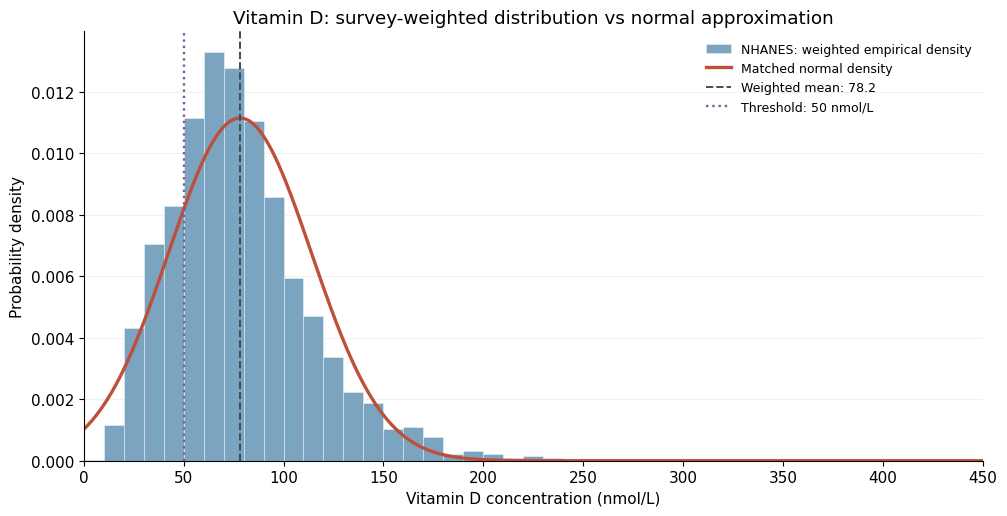

نمودار ذخیره شد: /mnt/data/figures/phase2/phase2_step3_weighted_histogram_normal.png


In [3]:
plt.rcParams.update({'font.size':11, 'axes.spines.top':False,'axes.spines.right':False})
fig, ax = plt.subplots(figsize=(10.2,5.3))
bins = np.arange(0, 451, 10)
ax.hist(x, bins=bins, weights=w_normalized, density=True, alpha=.66,
        color='#3776A1', edgecolor='white', linewidth=.45,
        label='NHANES: weighted empirical density')
grid_x = np.linspace(0, 450, 900)
ax.plot(grid_x, norm.pdf(grid_x, mean_w, sd_w), color='#BC503A',
        linewidth=2.4, label='Matched normal density')
ax.axvline(mean_w, color='#384F5B',linestyle='--',linewidth=1.4,
           label=f'Weighted mean: {mean_w:.1f}')
ax.axvline(THRESHOLD, color='#7D5D91',linestyle=':',linewidth=1.7,
           label='Threshold: 50 nmol/L')
ax.set(xlabel='Vitamin D concentration (nmol/L)', ylabel='Probability density',
       title='Vitamin D: survey-weighted distribution vs normal approximation')
ax.set_xlim(0,450)  # Show the entire observed range, including the 424 nmol/L extreme.
ax.set_ylim(bottom=0)
ax.grid(axis='y',alpha=.17)
ax.legend(frameon=False,fontsize=9)
fig.tight_layout()
plot1=figure_dir/'phase2_step3_weighted_histogram_normal.png'
fig.savefig(plot1,dpi=170,bbox_inches='tight')
plt.show()
print('نمودار ذخیره شد:',plot1)

<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۴. نمودار چندکی در برابر چندکی</h2>
<p>در این نمودار، چندک‌های تجربی وزن‌دار را با چندک‌های نظری توزیع نرمال برازش‌شده مقایسه می‌کنیم. اگر توزیع تقریباً نرمال باشد، نقاط باید نزدیک خط مرجع قرار گیرند. خمیدگی منظم یا فاصلهٔ زیاد در انتهای نمودار نشانهٔ ناسازگاری شکل تجربی با مدل نرمال است.</p>
<p>برای محاسبهٔ چندک‌های وزن‌دار از درون‌یابیِ موقعیت‌های تجمعی میانی وزن‌ها استفاده می‌کنیم؛ این تعریف در کل نوت‌بوک یکسان است.</p>
</div>

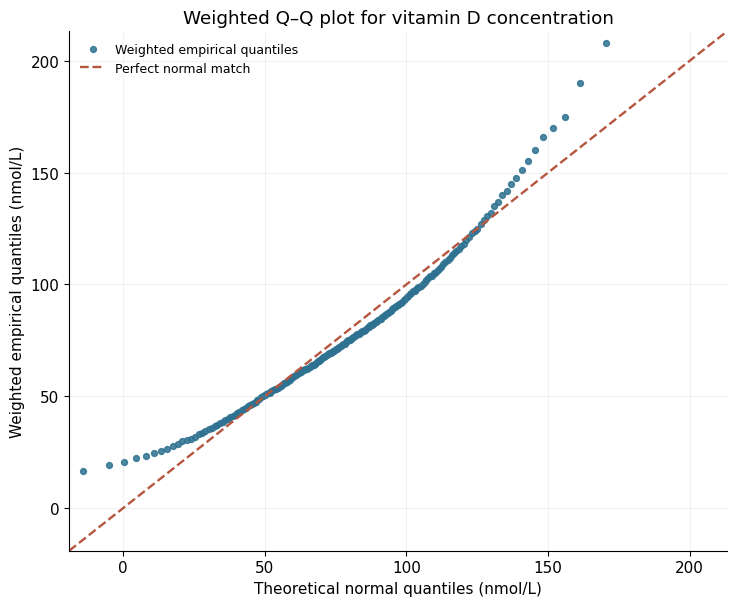

نمودار ذخیره شد: /mnt/data/figures/phase2/phase2_step3_weighted_qq.png


In [4]:
probabilities = np.linspace(.005,.995,199)
emp_q = weighted_quantile(x,w,probabilities)
normal_q = norm.ppf(probabilities, loc=mean_w, scale=sd_w)
fig, ax=plt.subplots(figsize=(7.5,6.2))
ax.scatter(normal_q,emp_q,s=18,alpha=.85,color='#2E7190',label='Weighted empirical quantiles')
axis_lo=min(normal_q.min(),emp_q.min())-5
axis_hi=max(normal_q.max(),emp_q.max())+5
ax.plot([axis_lo,axis_hi],[axis_lo,axis_hi],linestyle='--',color='#B6563F',lw=1.7,label='Perfect normal match')
ax.set(xlabel='Theoretical normal quantiles (nmol/L)',
       ylabel='Weighted empirical quantiles (nmol/L)',
       title='Weighted Q–Q plot for vitamin D concentration')
ax.set_xlim(axis_lo,axis_hi)
ax.set_ylim(axis_lo,axis_hi)
ax.grid(alpha=.17)
ax.legend(frameon=False,fontsize=9)
fig.tight_layout()
plot2=figure_dir/'phase2_step3_weighted_qq.png'
fig.savefig(plot2,dpi=170,bbox_inches='tight')
plt.show()
print('نمودار ذخیره شد:',plot2)

<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۵. مقایسهٔ احتمال‌های واقعی با تقریب نرمال</h2>
<p>برای سنجش کیفیت تقریب نرمال، سه ناحیه را مقایسه می‌کنیم: مقادیر منفی (که برای غلظت آزمایشگاهی از نظر فیزیکی ممکن نیستند)، زیر آستانهٔ ۵۰، و مقادیر بالاتر از ۱۵۰ نانومول بر لیتر. مقدار ۱۵۰ صرفاً یک آستانهٔ توصیفی ثابت برای بررسی دنبالهٔ راست است و در این پروژه به‌عنوان مرز تشخیصی به کار نمی‌رود.</p>
<p>تفاوت مهم این است که احتمال واقعی را مستقیماً از وزن‌های شرکت‌کنندگان محاسبه می‌کنیم، اما احتمال نظری را با تابع توزیع تجمعی مدل نرمال به دست می‌آوریم.</p>
</div>

$$\widehat{P}_{w}(D<t)=\frac{\sum_i w_i\,\mathbf 1(D_i<t)}{\sum_i w_i},\qquad
P_{\mathrm{normal}}(D<t)=\Phi\!\left(\frac{t-\widehat\mu_w}{\widehat\sigma_w}\right).$$

,ناحیه,احتمال تجربی وزن‌دار,احتمال مدل نرمال,اختلاف (واحد درصد)
0,مقادیر کمتر از صفر,0.00000,0.01444,-1.44353
1,مقادیر کمتر از ۵۰,0.20838,0.21538,-0.69954
2,مقادیر بیشتر از ۱۵۰,0.04050,0.02238,1.81140


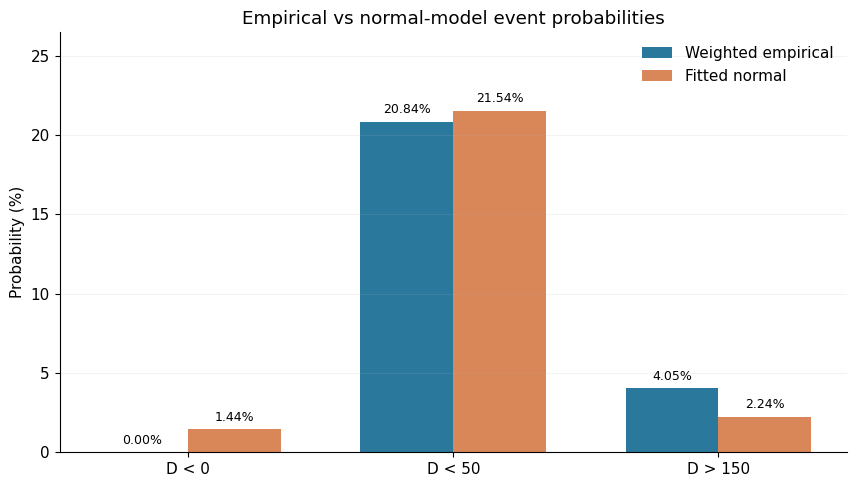

نمودار ذخیره شد: /mnt/data/figures/phase2/phase2_step3_empirical_vs_normal_probabilities.png


In [5]:
regions = ['D < 0','D < 50','D > 150']
empirical = np.array([
    np.sum(w_normalized[x<0]),
    np.sum(w_normalized[x<THRESHOLD]),
    np.sum(w_normalized[x>UPPER_TAIL]),
])
modeled = np.array([
    norm.cdf(0,mean_w,sd_w),
    norm.cdf(THRESHOLD,mean_w,sd_w),
    norm.sf(UPPER_TAIL,mean_w,sd_w),
])
compare = pd.DataFrame({
    'ناحیه': ['مقادیر کمتر از صفر','مقادیر کمتر از ۵۰','مقادیر بیشتر از ۱۵۰'],
    'احتمال تجربی وزن‌دار':empirical,
    'احتمال مدل نرمال':modeled,
    'اختلاف (واحد درصد)':100*(empirical-modeled),
})
display(compare.round(5))

fig,ax=plt.subplots(figsize=(8.7,5))
pos=np.arange(len(regions))
bar_w=.35
bars1=ax.bar(pos-bar_w/2,100*empirical,width=bar_w,label='Weighted empirical',color='#2B789D')
bars2=ax.bar(pos+bar_w/2,100*modeled,width=bar_w,label='Fitted normal',color='#D98758')
for bar in [*bars1,*bars2]:
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.35,
            f'{bar.get_height():.2f}%',ha='center',va='bottom',fontsize=9)
ax.set_xticks(pos,regions)
ax.set(ylabel='Probability (%)', title='Empirical vs normal-model event probabilities')
ax.set_ylim(0,max(100*empirical.max(),100*modeled.max())*1.23)
ax.grid(axis='y',alpha=.15)
ax.legend(frameon=False)
fig.tight_layout()
plot3=figure_dir/'phase2_step3_empirical_vs_normal_probabilities.png'
fig.savefig(plot3,dpi=170,bbox_inches='tight')
plt.show()
print('نمودار ذخیره شد:',plot3)

<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۶. مقادیر دورافتاده و محدودیت تفسیر</h2>
<p>برای علامت‌گذاری مقادیر دورافتاده از قاعدهٔ فاصلهٔ بین‌چارکی استفاده می‌کنیم. با توجه به راست‌چوله بودن توزیع، این معیار صرفاً نقاط قابل بررسی را مشخص می‌کند؛ <strong>دلیلی برای حذف خودکار آن‌ها نیست.</strong></p>
</div>

$$\operatorname{IQR}=Q_3-Q_1,\qquad
L=Q_1-1.5\operatorname{IQR},\qquad U=Q_3+1.5\operatorname{IQR}.$$

<div dir="rtl" style="text-align:right; line-height:1.9;">
<p>نکتهٔ دیگر این است که مقایسهٔ نموداری وزن‌دار، آزمون رسمی نرمال‌بودن یا برآورد خطای استاندارد مبتنی بر طرح پیچیدهٔ پیمایش نیست. از این نمودارها نتیجهٔ علّی یا استنباطی دربارهٔ تمام جمعیت نمی‌گیریم.</p>
</div>

In [6]:
print('چارک اول وزن‌دار:',round(float(q1_w),3))
print('چارک سوم وزن‌دار:',round(float(q3_w),3))
print('کران پایین قاعدهٔ بین‌چارکی:',round(float(lower_w),3))
print('کران بالا قاعدهٔ بین‌چارکی:',round(float(upper_w),3))
print('تعداد مقادیر خارج از کران‌ها:',int(out_w.sum()))
print('درصد وزن‌دار مقادیر خارج از کران‌ها:',round(100*float(w_normalized[out_w].sum()),3))
print('مشاهدهٔ کمینه و بیشینه:',round(float(x.min()),2),round(float(x.max()),2))

چارک اول وزن‌دار: 53.5
چارک سوم وزن‌دار: 97.0
کران پایین قاعدهٔ بین‌چارکی: -11.75
کران بالا قاعدهٔ بین‌چارکی: 162.25
تعداد مقادیر خارج از کران‌ها: 211
درصد وزن‌دار مقادیر خارج از کران‌ها: 2.758
مشاهدهٔ کمینه و بیشینه: 9.13 424.0


<div dir="rtl" style="text-align:right; line-height:1.9;">
<h2>۷. جمع‌بندی علمی و ذخیرهٔ خروجی‌ها</h2>
<p>در جمع‌بندی به چهار شاهد توجه می‌کنیم: شکل هیستوگرام، چولگی، انحراف نقاط از خط مرجع نمودار چندکی و اختلاف احتمال‌های انتهایی با مدل نرمال. چون توزیع به سمت راست چوله است، مدل نرمال را فقط یک تقریب توصیفی در نظر می‌گیریم و استفاده از آن برای احتمال‌های انتهایی نیازمند احتیاط است.</p>
<p>این بررسی توزیع و احتمال‌ها را پوشش می‌دهد. در گام بعد، امید ریاضی و واریانس را به‌عنوان ویژگی‌های متغیر تصادفی به‌صورت آموزشی عمیق‌تر بررسی خواهیم کرد و سپس کوواریانس با متغیر کمی دوم را محاسبه می‌کنیم.</p>
<p>فایل‌های خروجی شامل سه نمودار، دو جدول خلاصه و یادداشت علمی است. دادهٔ ردیفی و شناسه‌های افراد در خروجی ذخیره نمی‌شوند.</p>
</div>

In [7]:
# Only aggregated summaries are saved; individual participant-level records are never exported.
summary_for_csv = pd.DataFrame({
    'measure':['sample_n','raw_mean','weighted_mean','raw_median','weighted_median',
               'raw_sd_descriptive','weighted_sd_descriptive', 'raw_skewness','weighted_skewness',
               'weighted_excess_kurtosis','weighted_q1','weighted_q3','weighted_iqr_low',
               'weighted_iqr_high','outlier_count_weighted_rule','outlier_weighted_share',
               'min_observed','max_observed'],
    'value':[N,mean_raw,mean_w,median_raw,median_w,sd_raw,sd_w,skew_raw,skew_w,
             kurt_w,q1_w,q3_w,lower_w,upper_w,int(out_w.sum()),float(w_normalized[out_w].sum()),
             x.min(),x.max()]
})
summary_path=report_dir/'phase2_step3_distribution_summary.csv'
prob_path=report_dir/'phase2_step3_probability_comparison.csv'
summary_for_csv.to_csv(summary_path,index=False,encoding='utf-8-sig')
compare.to_csv(prob_path,index=False,encoding='utf-8-sig')

notes=f'''# گزارش گام سوم فاز دوم — توزیع ویتامین دی

<div dir="rtl" style="text-align:right; line-height:1.9;">

**جامعهٔ تحلیلی:** {N:,} بزرگسال با مقدار ویتامین دی و وزن خون‌گیری معتبر. همهٔ محاسبات روی دادهٔ ادغام‌شدهٔ فاز اول انجام شده‌اند.

**میانگین و انحراف معیار وزن‌دار:** به‌ترتیب {mean_w:.2f} و {sd_w:.2f} نانومول بر لیتر. میانهٔ وزن‌دار {median_w:.2f} نانومول بر لیتر و چولگی وزن‌دار {skew_w:.3f} است.

**مقایسهٔ احتمال‌ها:** سهم وزن‌دار مقادیر زیر ۵۰ برابر {100*empirical[1]:.2f} درصد است؛ مدل نرمال متناظر {100*modeled[1]:.2f} درصد پیش‌بینی می‌کند. سهم وزن‌دار مقادیر بیش از ۱۵۰ برابر {100*empirical[2]:.2f} درصد است، ولی مدل نرمال {100*modeled[2]:.2f} درصد برآورد می‌کند. مدل نرمال همچنین برای مقادیر منفی، احتمال {100*modeled[0]:.2f} درصد اختصاص می‌دهد، در حالی که غلظت منفی ممکن نیست.

**مقادیر دورافتاده:** با استفاده از چارک‌های وزن‌دار و قاعدهٔ فاصلهٔ بین‌چارکی، کران بالا {upper_w:.2f} نانومول بر لیتر است. تعداد {int(out_w.sum())} مشاهده خارج از کران‌های تعیین‌شده قرار دارد و سهم وزن‌دار آن‌ها {100*float(w_normalized[out_w].sum()):.2f} درصد است. هیچ مشاهده‌ای خودکار حذف نشده است.

**جمع‌بندی:** توزیع دارای چولگی راست و دنبالهٔ بالایی سنگین‌تر از مدل نرمال برازش‌شده است؛ بنابراین مدل نرمال توصیف دقیقی از همهٔ بخش‌های توزیع نیست و به‌ویژه برای احتمال‌های دنبالهٔ راست باید با احتیاط استفاده شود.

**محدودیت:** این واریانس وزن‌دار، واریانس توصیفی توزیع مقادیر است، نه واریانس برآوردگر تحت طراحی نمونه‌گیری NHANES؛ در این گام فاصلهٔ اطمینان یا آزمون فرض رسمی ارائه نمی‌شود.

**روش محاسبه:** وزن‌ها در جامعه تحلیلی نرمال شدند؛ چندک‌های وزن‌دار با درون‌یابیِ توزیع تجمعیِ وزن‌دار در موقعیت میانی وزن‌ها به دست آمدند؛ منحنی نرمال با میانگین و انحراف معیار توصیفی وزن‌دار ساخته شد. آستانهٔ ۱۵۰ فقط برای بررسی بخش انتهایی راست انتخاب شده و آستانهٔ تشخیصی نیست.

</div>
'''
notes_path=report_dir/'step3_normal_distribution_notes.md'
notes_path.write_text(notes,encoding='utf-8')

for p in [plot1,plot2,plot3,summary_path,prob_path,notes_path]:
    assert p.is_file(),p
    print('ذخیره شد:',p)
print('گام سوم با موفقیت اجرا شد.')

ذخیره شد: /mnt/data/figures/phase2/phase2_step3_weighted_histogram_normal.png
ذخیره شد: /mnt/data/figures/phase2/phase2_step3_weighted_qq.png
ذخیره شد: /mnt/data/figures/phase2/phase2_step3_empirical_vs_normal_probabilities.png
ذخیره شد: /mnt/data/reports/phase2/phase2_step3_distribution_summary.csv
ذخیره شد: /mnt/data/reports/phase2/phase2_step3_probability_comparison.csv
ذخیره شد: /mnt/data/reports/phase2/step3_normal_distribution_notes.md
گام سوم با موفقیت اجرا شد.
